In [3]:
from pathlib import Path

import tensorflow as tf
import matplotlib.pyplot as plt

In [7]:
DATA_PATH = Path("../data/raw/seg_train")

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

In [9]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 17034 files belonging to 6 classes.
Using 13628 files for training.


In [10]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 17034 files belonging to 6 classes.
Using 3406 files for validation.


In [11]:
half = len(val_ds) // 2

test_ds = val_ds.take(half)
val_ds = val_ds.skip(half)

In [13]:
class_names = train_ds.class_names

print(class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [14]:
NUM_CLASSES = len(class_names)

print(NUM_CLASSES)

6


In [16]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [17]:
model = tf.keras.Sequential([
    
    tf.keras.Input(shape=(150, 150, 3)),
    
    data_augmentation,
    
    tf.keras.layers.Rescaling(1./255),
    
    tf.keras.layers.Conv2D(
        32,
        3,
        activation="relu"
    ),
    
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(
        64,
        3,
        activation="relu"
    ),
    
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(
        128,
        3,
        activation="relu"
    ),
    
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Flatten(),
    
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),
    
    tf.keras.layers.Dropout(0.5),
    
    tf.keras.layers.Dense(
        6,
        activation="softmax"
    )
])

In [19]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.8028 - loss: 0.5603 - val_accuracy: 0.7924 - val_loss: 0.6037
Epoch 2/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.8095 - loss: 0.5412 - val_accuracy: 0.7953 - val_loss: 0.5867
Epoch 3/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 49s 115ms/step - accuracy: 0.8138 - loss: 0.5318 - val_accuracy: 0.8135 - val_loss: 0.5403
Epoch 4/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 48s 114ms/step - accuracy: 0.8171 - loss: 0.5185 - val_accuracy: 0.8216 - val_loss: 0.5747
Epoch 5/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 49s 115ms/step - accuracy: 0.8210 - loss: 0.5073 - val_accuracy: 0.8105 - val_loss: 0.5565
Epoch 6/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 49s 116ms/step - accuracy: 0.8244 - loss: 0.4962 - val_accuracy: 0.7953 - val_loss: 0.6058
Epoch 7/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 81s 113ms/step - accuracy: 0.8278 - loss: 0.4912 - val_accuracy: 0.8386 - val_loss: 0.4717
Epoch 8/10
426/426 ━━━━━━━━━━━━━━━━━━━━ 49s 115ms/step - accuracy: 0.8326 - loss: 0

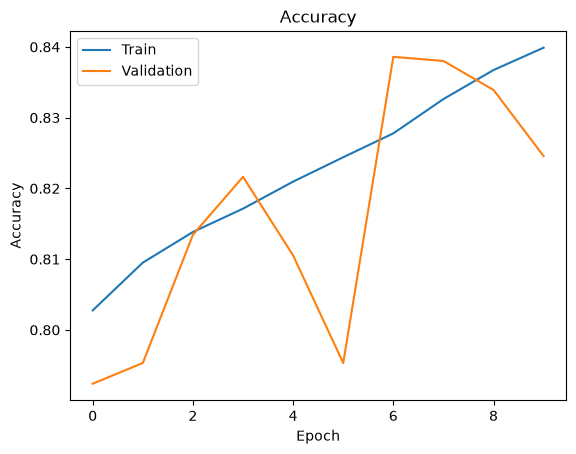

In [24]:
plt.plot(
    history.history["accuracy"],
    label="Train"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.title("Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()

plt.show()

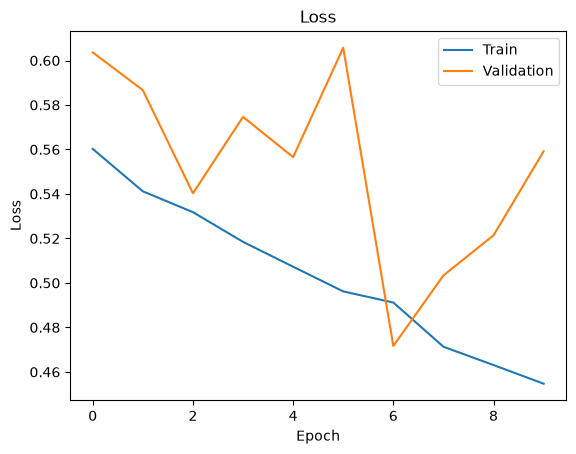

In [25]:
plt.plot(
    history.history["loss"],
    label="Train"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.title("Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()

plt.show()

In [26]:
val_loss, val_accuracy = model.evaluate(
    val_ds
)

print(
    "Validation accuracy:",
    val_accuracy
)

54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8246 - loss: 0.5640
Validation accuracy: 0.8245614171028137
